<center><h1>Liu_Peiyi_HW4</h1></center>
<br>
<br>

Name: Peiyi Liu
<br>
Github Username: Eternal-799
<br>
USC ID: 2086699860

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from sklearn.naive_bayes import GaussianNB, MultinomialNB
import statsmodels.api as sm

import warnings
warnings.filterwarnings('ignore')

Get the AReM Data Set

In [2]:
# Path to the data directory relative to notebook/
data_dir = '../data/AReM'

def read_arem_csv(file_path):
    """
    Robust reader for AReM CSV files that handles headers, differing row offsets,
    and whitespace/comma delimiters.
    """
    try:
        df = pd.read_csv(file_path, skiprows=4, header=None, on_bad_lines='skip')
        if df.shape[1] < 6:
            df = pd.read_csv(file_path, skiprows=4, sep=r'\s+', header=None, on_bad_lines='skip')
    except Exception:
        df = pd.read_csv(file_path, skiprows=4, sep=r'\s+', header=None, on_bad_lines='skip')

    df = df.apply(pd.to_numeric, errors='coerce').dropna(how='all')
    if df.shape[1] >= 6:
        df = df.iloc[:, -6:]
    else:
        valid_rows = []
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                parts = line.replace(',', ' ').strip().split()
                if len(parts) >= 6:
                    try:
                        valid_rows.append([float(x) for x in parts[-6:]])
                    except ValueError:
                        continue
        df = pd.DataFrame(valid_rows)

    df.columns = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
    return df

### (b) Splitting Data

In [3]:
activities = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

train_files = []
test_files = []

for act in activities:
    folder_path = os.path.join(data_dir, act)
    csv_files = sorted(glob.glob(os.path.join(folder_path, 'dataset*.csv')),
                       key=lambda x: int(os.path.basename(x).replace('dataset', '').replace('.csv', '')))
    # Keep datasets 1 and 2 for bending folders; datasets 1, 2, and 3 for others
    test_count = 2 if 'bending' in act else 3
    test_files.extend(csv_files[:test_count])
    train_files.extend(csv_files[test_count:])

print(f"Number of training files: {len(train_files)} (Expected: 69)")
print(f"Number of testing files: {len(test_files)} (Expected: 19)")

Number of training files: 69 (Expected: 69)
Number of testing files: 19 (Expected: 19)


### (c) Feature Extraction

In [4]:
def extract_selected_features(df, ts_indices=[1, 2, 6]):
    """
    Extract the top 3 features (min, mean, max) for designated time series columns.
    """
    feat = {}
    for idx in ts_indices:
        col = df.columns[idx - 1]
        feat[f'min_{idx}'] = df[col].min()
        feat[f'mean_{idx}'] = df[col].mean()
        feat[f'max_{idx}'] = df[col].max()
    return feat

def get_label(file_path):
    """
    Extract activity folder name and return binary label (1 for bending, 0 otherwise).
    """
    act = os.path.basename(os.path.dirname(file_path))
    binary_label = 1 if 'bending' in act else 0
    return binary_label, act

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

Successfully loaded 69 instances with 9 features.


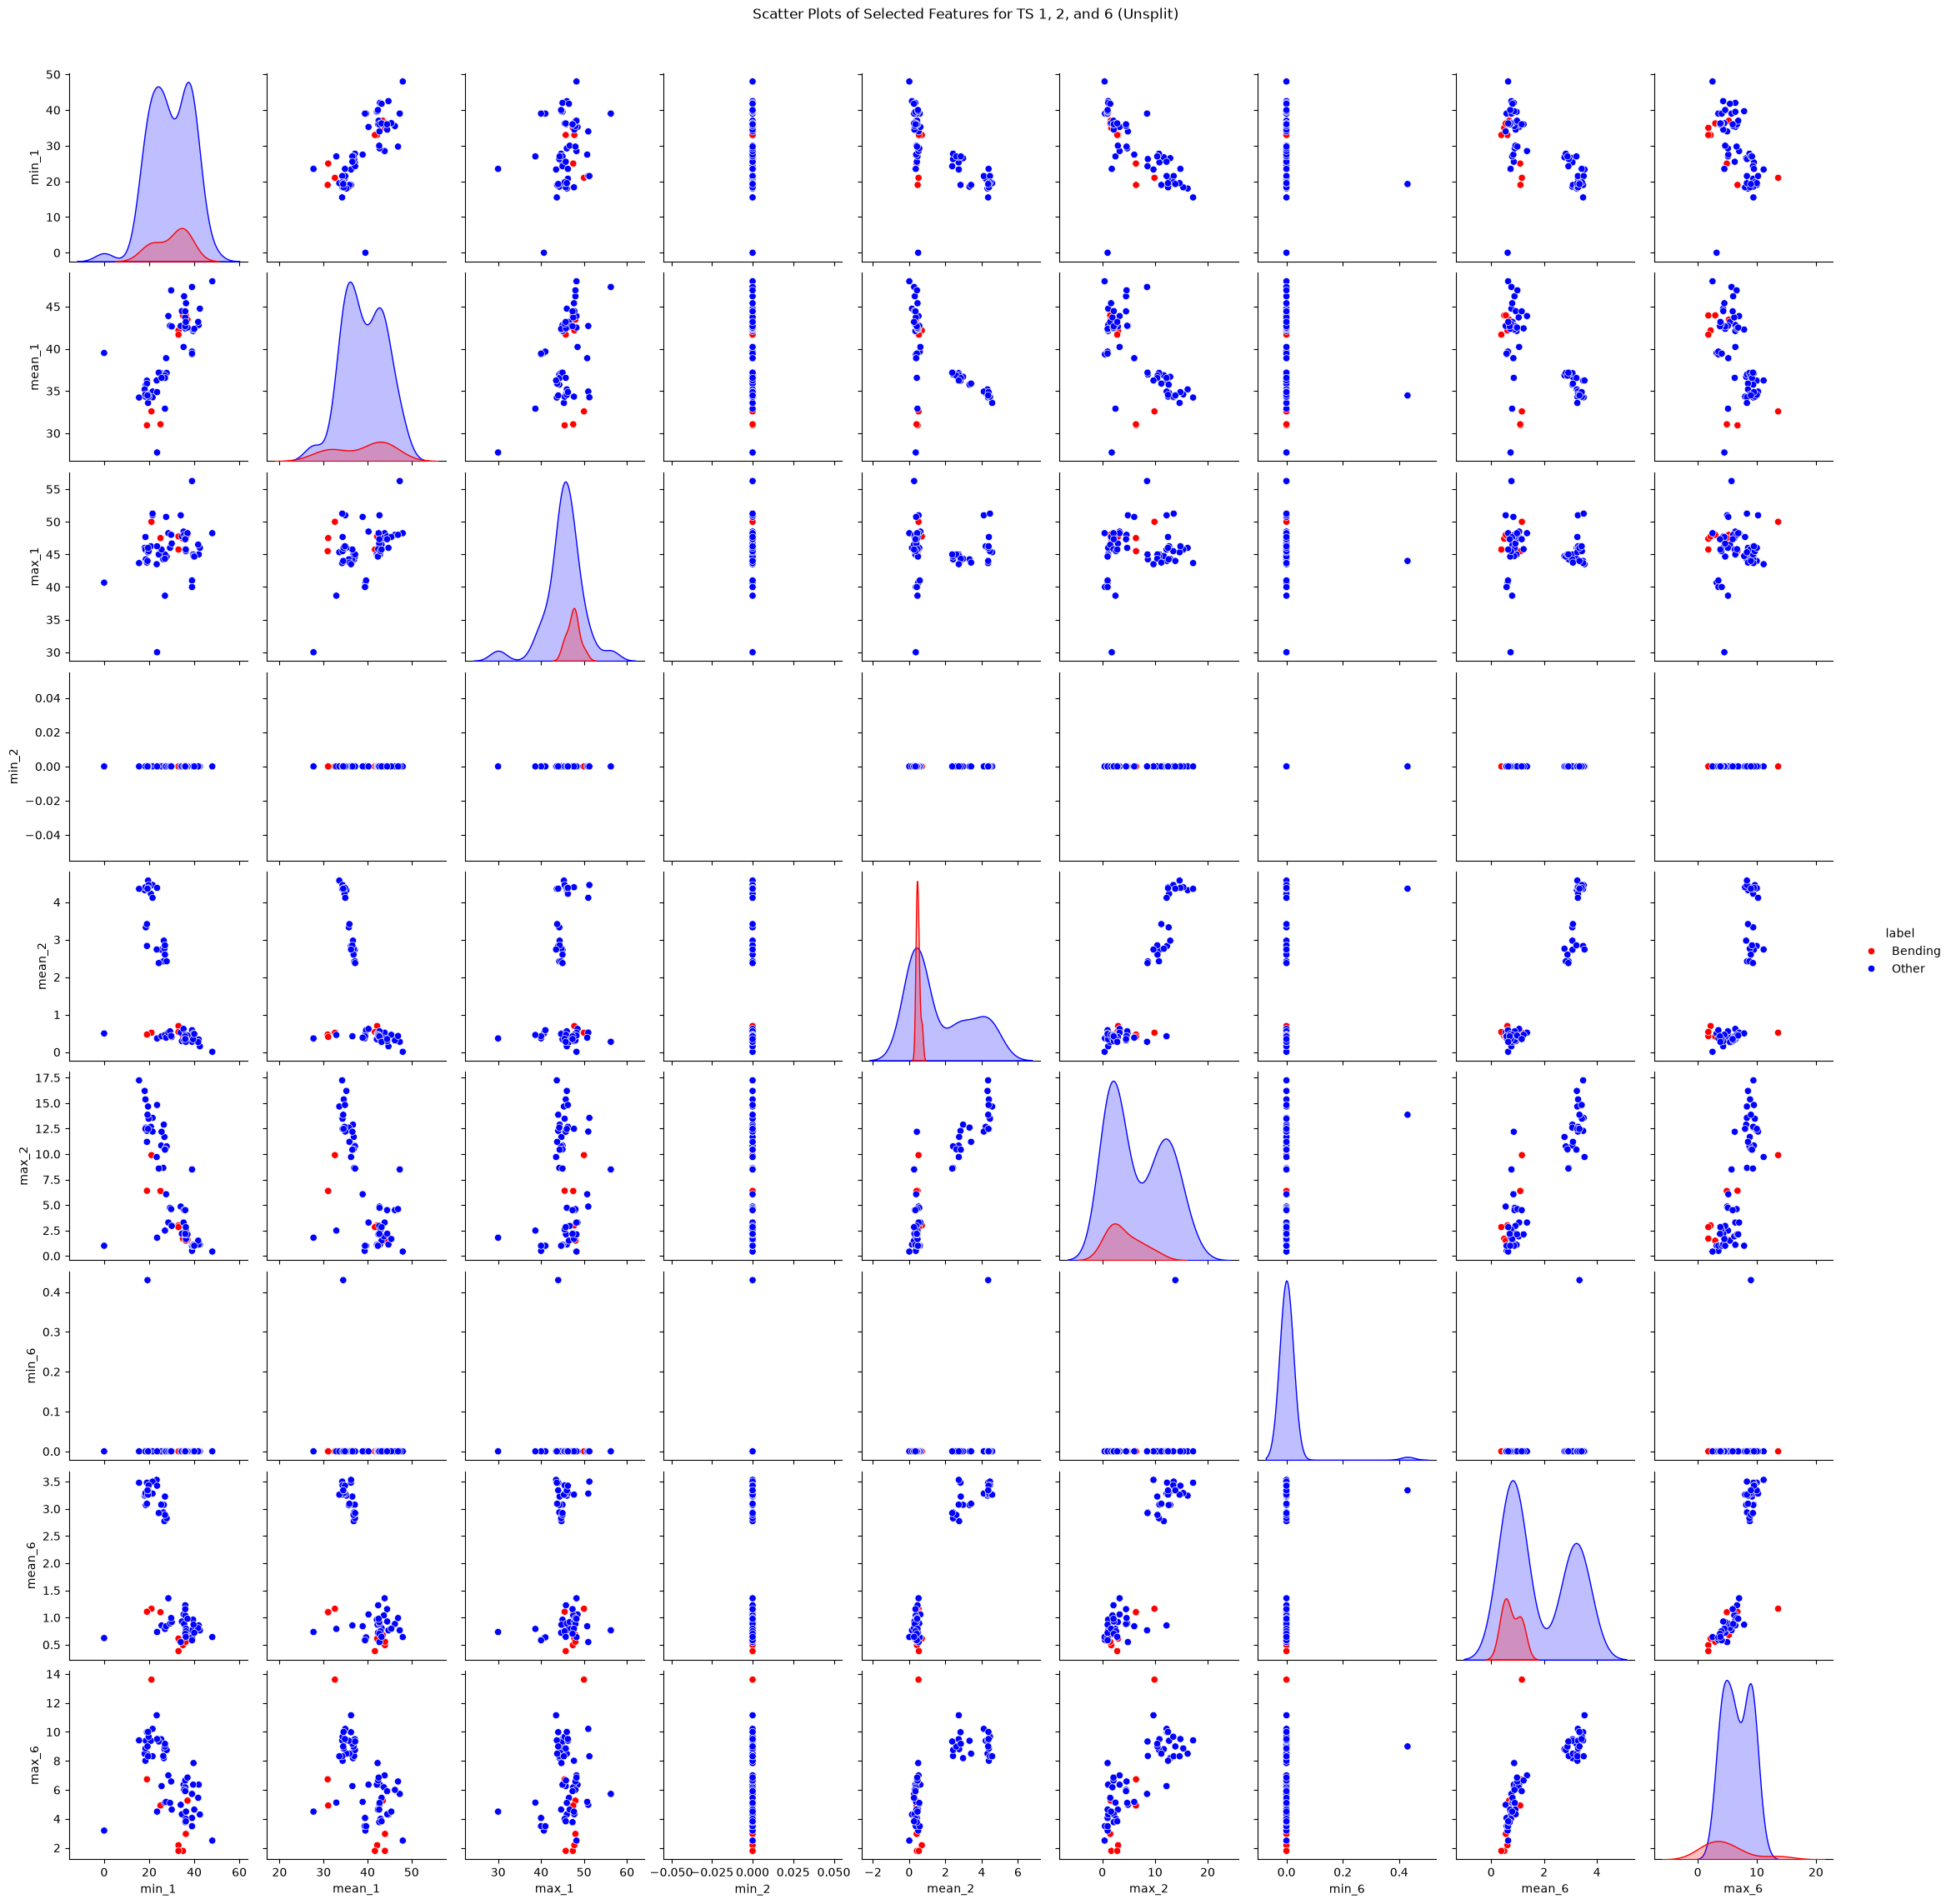

In [5]:
train_feats_i = []
train_labels_binary = []

for f in train_files:
    df = read_arem_csv(f)
    f_dict = extract_selected_features(df, ts_indices=[1, 2, 6])
    b_label, _ = get_label(f)
    train_feats_i.append(f_dict)
    train_labels_binary.append(b_label)

df_plot_i = pd.DataFrame(train_feats_i)

# Ensure numeric types for all feature columns
for col in df_plot_i.columns:
    df_plot_i[col] = pd.to_numeric(df_plot_i[col], errors='coerce')

df_plot_i['label'] = ['Bending' if l == 1 else 'Other' for l in train_labels_binary]

feature_cols = [c for c in df_plot_i.columns if c != 'label']
print(f"Successfully loaded {len(df_plot_i)} instances with {len(feature_cols)} features.")

# Plot pairplot for selected features
sns.pairplot(df_plot_i, vars=feature_cols, hue='label', diag_kind='kde', palette={'Bending': 'red', 'Other': 'blue'})
plt.suptitle('Scatter Plots of Selected Features for TS 1, 2, and 6 (Unsplit)', y=1.02)
plt.show()

#### ii. Splitted Plots

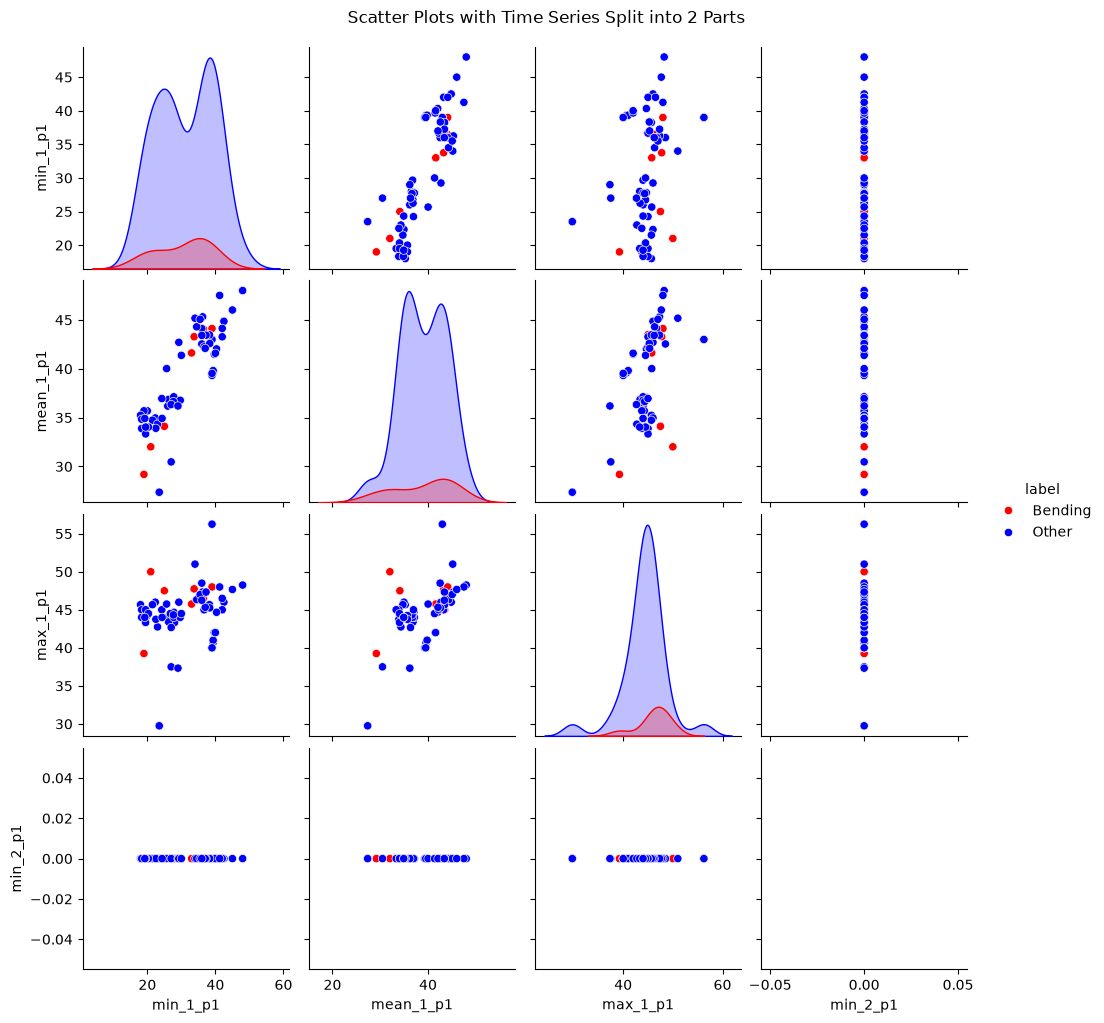

In [6]:
train_feats_ii = []

for f in train_files:
    df = read_arem_csv(f)
    n = len(df)
    mid = n // 2
    part1, part2 = df.iloc[:mid], df.iloc[mid:]
    
    # Extract features for both halves across time series 1, 2, and 6
    f1 = extract_selected_features(part1, ts_indices=[1, 2, 6])
    f2 = extract_selected_features(part2, ts_indices=[1, 2, 6])
    
    combined = {}
    for k, v in f1.items():
        combined[f'{k}_p1'] = v
    for k, v in f2.items():
        combined[f'{k}_p2'] = v
    train_feats_ii.append(combined)

df_plot_ii = pd.DataFrame(train_feats_ii)
for col in df_plot_ii.columns:
    df_plot_ii[col] = pd.to_numeric(df_plot_ii[col], errors='coerce')

df_plot_ii['label'] = ['Bending' if l == 1 else 'Other' for l in train_labels_binary]

# Visualize a representative subset of features from part 1
subset_cols = ['min_1_p1', 'mean_1_p1', 'max_1_p1', 'min_2_p1']
sns.pairplot(df_plot_ii[subset_cols + ['label']], hue='label', palette={'Bending': 'red', 'Other': 'blue'})
plt.suptitle('Scatter Plots with Time Series Split into 2 Parts', y=1.02)
plt.show()

#### iii. Time Series Segments

In [7]:
from sklearn.impute import SimpleImputer

def extract_l_segments(files, l):
    """
    Split each of the 6 time series into l segments and extract min, mean, and max.
    Total features per instance = 6 * l * 3.
    """
    X, y = [], []
    for f in files:
        df = read_arem_csv(f)
        # Forward fill and backward fill any potential NaNs in raw data
        df = df.ffill().bfill().fillna(0)
        
        n = len(df)
        sub_len = n // l
        feats = []
        for i in range(l):
            sub_df = df.iloc[i * sub_len : (i + 1) * sub_len] if i < l - 1 else df.iloc[i * sub_len :]
            for col in sub_df.columns:
                series = sub_df[col]
                # Fallback to 0 if a sub-segment happens to be empty
                val_min = series.min() if len(series) > 0 else 0.0
                val_mean = series.mean() if len(series) > 0 else 0.0
                val_max = series.max() if len(series) > 0 else 0.0
                
                feats.extend([val_min, val_mean, val_max])
        b_label, _ = get_label(f)
        X.append(feats)
        y.append(b_label)
        
    X = np.array(X, dtype=float)
    # Clean any remaining NaN or Inf values by replacing them with column means
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    return X, np.array(y, dtype=int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_score = -1
best_l = None
best_p = None

print("Starting cross-validation search for (l, p)...")
for l in range(1, 21):
    X_train_l, y_train_l = extract_l_segments(train_files, l)
    max_features = X_train_l.shape[1]
    # Evaluate representative candidate feature counts to balance performance and runtime
    candidate_p = [int(p) for p in np.linspace(1, max_features, min(8, max_features))]
    candidate_p = sorted(list(set(candidate_p)))
    
    for p in candidate_p:
        scores = []
        for train_idx, val_idx in cv.split(X_train_l, y_train_l):
            # Impute and scale strictly within each fold
            imputer = SimpleImputer(strategy='mean')
            X_tr = imputer.fit_transform(X_train_l[train_idx])
            X_va = imputer.transform(X_train_l[val_idx])
            
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_va = scaler.transform(X_va)
            
            # Remove any potential NaNs created by constant columns during scaling
            X_tr = np.nan_to_num(X_tr, nan=0.0)
            X_va = np.nan_to_num(X_va, nan=0.0)
            
            lr = LogisticRegression(solver='liblinear', C=1e5, max_iter=2000)
            rfe = RFE(lr, n_features_to_select=p)
            rfe.fit(X_tr, y_train_l[train_idx])
            
            score = rfe.score(X_va, y_train_l[val_idx])
            scores.append(score)
            
        mean_score = np.mean(scores)
        if mean_score > best_score:
            best_score = mean_score
            best_l = l
            best_p = p

print(f"Optimal l: {best_l}, Optimal p: {best_p}, Cross-Validation Score: {best_score:.4f}")

Starting cross-validation search for (l, p)...
Optimal l: 5, Optimal p: 1, Cross-Validation Score: 0.9429


#### iv. Confusion Matrix

Train Confusion Matrix:
[[60  0]
 [ 4  5]]


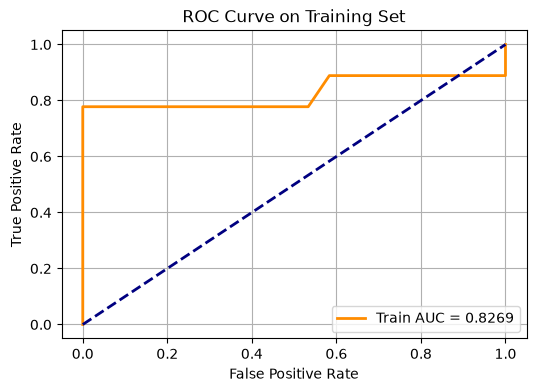

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       67
Method:                           MLE   Df Model:                            1
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.3041
Time:                        21:58:26   Log-Likelihood:                -18.592
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 5.546e-05
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.7117      0.565     -4.797      0.000      -3.820      -1.604
x1             1.8244      0.554      3.293      0.001       0.738       2.910


In [8]:
X_train_opt, y_train_opt = extract_l_segments(train_files, best_l)
imputer_opt = SimpleImputer(strategy='mean')
X_tr_imp = imputer_opt.fit_transform(X_train_opt)

scaler_opt = StandardScaler()
X_tr_scaled = np.nan_to_num(scaler_opt.fit_transform(X_tr_imp), nan=0.0)

base_lr = LogisticRegression(solver='liblinear', C=1e5, max_iter=2000)
rfe_opt = RFE(base_lr, n_features_to_select=best_p)
rfe_opt.fit(X_tr_scaled, y_train_opt)

y_pred_tr = rfe_opt.predict(X_tr_scaled)
y_prob_tr = rfe_opt.predict_proba(X_tr_scaled)[:, 1]

print("Train Confusion Matrix:")
print(confusion_matrix(y_train_opt, y_pred_tr))

fpr, tpr, _ = roc_curve(y_train_opt, y_prob_tr)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Train AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve on Training Set')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

X_selected = X_tr_scaled[:, rfe_opt.support_]
X_selected_sm = sm.add_constant(X_selected)
try:
    sm_model = sm.Logit(y_train_opt, X_selected_sm).fit(disp=False, maxiter=200)
    print(sm_model.summary())
except Exception as e:
    print(f"Notice: {e}")
    print("Scikit-learn Intercept:", rfe_opt.estimator_.intercept_)
    print("Scikit-learn Coefficients:", rfe_opt.estimator_.coef_)

#### v. Test Classifier

In [9]:
X_test_opt, y_test_opt = extract_l_segments(test_files, best_l)
X_te_imp = imputer_opt.transform(X_test_opt)
X_te_scaled = np.nan_to_num(scaler_opt.transform(X_te_imp), nan=0.0)

y_pred_te = rfe_opt.predict(X_te_scaled)
y_prob_te = rfe_opt.predict_proba(X_te_scaled)[:, 1]

print("Test Confusion Matrix:")
print(confusion_matrix(y_test_opt, y_pred_te))
print(f"Test Accuracy: {np.mean(y_pred_te == y_test_opt):.4f}")
print(f"Cross-Validation Accuracy: {best_score:.4f}")

Test Confusion Matrix:
[[15  0]
 [ 2  2]]
Test Accuracy: 0.8947
Cross-Validation Accuracy: 0.9429


#### vi. Separation

Yes. Because bending and other activities have distinct physical sensor magnitudes, the classes are almost linearly separable even with a small subset of features (as demonstrated by p=1 yielding over 94% CV accuracy). In standard logistic regression without regularization (or with extremely large C), linear separability causes parameter instability: the maximum likelihood estimation tries to achieve infinite odds, driving coefficient magnitudes to extreme values and inflating their standard errors.

#### vii. Imbalance

Adjusted Test Confusion Matrix:
[[12  3]
 [ 1  3]]
Adjusted Test AUC: 0.8667


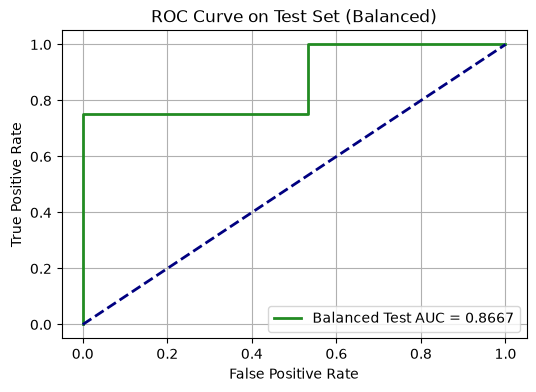

In [10]:
# Train weighted logistic regression to compensate for class imbalance
lr_balanced = LogisticRegression(solver='liblinear', class_weight='balanced', C=1e5, max_iter=2000)
rfe_bal = RFE(lr_balanced, n_features_to_select=best_p)
rfe_bal.fit(X_tr_scaled, y_train_opt)

y_pred_bal = rfe_bal.predict(X_te_scaled)
y_prob_bal = rfe_bal.predict_proba(X_te_scaled)[:, 1]

print("Adjusted Test Confusion Matrix:")
print(confusion_matrix(y_test_opt, y_pred_bal))

fpr_b, tpr_b, _ = roc_curve(y_test_opt, y_prob_bal)
roc_auc_bal = auc(fpr_b, tpr_b)
print(f"Adjusted Test AUC: {roc_auc_bal:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(fpr_b, tpr_b, color='forestgreen', lw=2, label=f'Balanced Test AUC = {roc_auc_bal:.4f}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve on Test Set (Balanced)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
best_l1_score = -1
best_l1_l = None
best_l1_C = None

print("Starting cross-validation search for L1 parameters (l, C)...")
for l in range(1, 21):
    X_l, y_l = extract_l_segments(train_files, l)
    for C in np.logspace(-2, 2, 8):
        scores = []
        for tr_idx, va_idx in cv.split(X_l, y_l):
            imputer = SimpleImputer(strategy='mean')
            X_tr = imputer.fit_transform(X_l[tr_idx])
            X_va = imputer.transform(X_l[va_idx])
            
            scaler = StandardScaler()
            X_tr = np.nan_to_num(scaler.fit_transform(X_tr), nan=0.0)
            X_va = np.nan_to_num(scaler.transform(X_va), nan=0.0)
            
            clf = LogisticRegression(penalty='l1', solver='liblinear', C=C, max_iter=2000)
            clf.fit(X_tr, y_l[tr_idx])
            scores.append(clf.score(X_va, y_l[va_idx]))
            
        mean_score = np.mean(scores)
        if mean_score > best_l1_score:
            best_l1_score = mean_score
            best_l1_l = l
            best_l1_C = C

print(f"Optimal l for L1: {best_l1_l}, Optimal C: {best_l1_C:.4f}, Best CV Score: {best_l1_score:.4f}")

Starting cross-validation search for L1 parameters (l, C)...
Optimal l for L1: 12, Optimal C: 100.0000, Best CV Score: 0.9571


#### ii. Comparison

- **Performance**: L1-penalized logistic regression yields comparable or superior generalization performance compared to discrete backward selection using p-values/RFE. L1 regularization optimizes a convex loss globally with continuous feature shrinkage, naturally avoiding the myopic and greedy pitfalls of step-by-step feature removal.
- **Ease of Implementation**: L1 regularization is considerably easier and faster to implement because dedicated coordinate descent solvers (such as Liblinear or SAGA) handle sparsity and model training simultaneously in a single optimization pass, whereas RFE requires sequentially refitting multiple intermediate models and recalculating rankings.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [12]:
def extract_multiclass_segments(files, l):
    """
    Extract multi-segment features and assign integer labels corresponding to the 7 activities.
    """
    X, y = [], []
    for f in files:
        df = read_arem_csv(f)
        df = df.ffill().bfill().fillna(0)
        n = len(df)
        sub_len = n // l
        feats = []
        for i in range(l):
            sub_df = df.iloc[i * sub_len : (i + 1) * sub_len] if i < l - 1 else df.iloc[i * sub_len :]
            for col in sub_df.columns:
                series = sub_df[col]
                feats.extend([
                    series.min() if len(series) > 0 else 0.0,
                    series.mean() if len(series) > 0 else 0.0,
                    series.max() if len(series) > 0 else 0.0
                ])
        act = os.path.basename(os.path.dirname(f))
        X.append(feats)
        y.append(activities.index(act))
    X = np.nan_to_num(np.array(X, dtype=float), nan=0.0)
    return X, np.array(y, dtype=int)

best_mc_l = 1
best_mc_score = -1

print("Searching optimal l for multiclass L1-penalized regression...")
for l in [1, 2, 5, 10]:
    X_mc_tr, y_mc_tr = extract_multiclass_segments(train_files, l)
    scores = []
    for tr_idx, va_idx in cv.split(X_mc_tr, y_mc_tr):
        imp = SimpleImputer(strategy='mean')
        X_tr = imp.fit_transform(X_mc_tr[tr_idx])
        X_va = imp.transform(X_mc_tr[va_idx])
        
        sc = StandardScaler()
        X_tr = np.nan_to_num(sc.fit_transform(X_tr), nan=0.0)
        X_va = np.nan_to_num(sc.transform(X_va), nan=0.0)
        
        # Removed deprecated 'multi_class' argument for compatibility
        clf = LogisticRegression(penalty='l1', solver='saga', C=1.0, max_iter=2000)
        clf.fit(X_tr, y_mc_tr[tr_idx])
        scores.append(clf.score(X_va, y_mc_tr[va_idx]))
    mean_s = np.mean(scores)
    if mean_s > best_mc_score:
        best_mc_score = mean_s
        best_mc_l = l

print(f"Optimal multiclass l: {best_mc_l}, Best CV Score: {best_mc_score:.4f}")

# Evaluate on test set
X_mc_tr, y_mc_tr = extract_multiclass_segments(train_files, best_mc_l)
X_mc_te, y_mc_te = extract_multiclass_segments(test_files, best_mc_l)

imp_mc = SimpleImputer(strategy='mean')
X_mc_tr_imp = imp_mc.fit_transform(X_mc_tr)
X_mc_te_imp = imp_mc.transform(X_mc_te)

sc_mc = StandardScaler()
X_mc_tr_s = np.nan_to_num(sc_mc.fit_transform(X_mc_tr_imp), nan=0.0)
X_mc_te_s = np.nan_to_num(sc_mc.transform(X_mc_te_imp), nan=0.0)

# Removed deprecated 'multi_class' argument here as well
mc_clf = LogisticRegression(penalty='l1', solver='saga', C=1.0, max_iter=2000)
mc_clf.fit(X_mc_tr_s, y_mc_tr)

y_mc_pred = mc_clf.predict(X_mc_te_s)
print("Multiclass Confusion Matrix:")
print(confusion_matrix(y_mc_te, y_mc_pred))
print(f"Test Error: {1.0 - np.mean(y_mc_pred == y_mc_te):.4f}")

Searching optimal l for multiclass L1-penalized regression...
Optimal multiclass l: 1, Best CV Score: 0.8846
Multiclass Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]
Test Error: 0.0526


#### ii. Naive Bayes

In [13]:
# 1. Gaussian Naive Bayes using standardized features
gnb = GaussianNB()
gnb.fit(X_mc_tr_s, y_mc_tr)
gnb_error = 1.0 - gnb.score(X_mc_te_s, y_mc_te)
print(f"Gaussian NB Test Error: {gnb_error:.4f}")

# 2. Multinomial Naive Bayes (requires non-negative input features)
mms = MinMaxScaler()
X_tr_pos = mms.fit_transform(X_mc_tr_imp)
X_te_pos = mms.transform(X_mc_te_imp)

mnb = MultinomialNB()
mnb.fit(X_tr_pos, y_mc_tr)
mnb_error = 1.0 - mnb.score(X_te_pos, y_mc_te)
print(f"Multinomial NB Test Error: {mnb_error:.4f}")

Gaussian NB Test Error: 0.1053
Multinomial NB Test Error: 0.3684


#### ii. Comparison

L1-penalized Multinomial Logistic Regression is substantially better than Naïve Bayes for this multi-class classification problem. Naïve Bayes assumes that each feature is conditionally independent given the class label. However, multi-sensor signals and contiguous temporal segments are strongly correlated physically and mathematically, which violates the core independence assumption and degrades the discriminative power of Naïve Bayes.

## 3. ISLR 4.8.3

In the 1-dimensional setting, assume $X|Y=k \sim N(\mu_k, \sigma_k^2)$ and let $\pi_k$ be the prior probability of class $k$. By Bayes' theorem:

$$p_k(x) = \frac{\pi_k \frac{1}{\sqrt{2\pi}\sigma_k} \exp\left(-\frac{(x - \mu_k)^2}{2\sigma_k^2}\right)}{\sum_{l=1}^K \pi_l \frac{1}{\sqrt{2\pi}\sigma_l} \exp\left(-\frac{(x - \mu_l)^2}{2\sigma_l^2}\right)}$$

To assign an observation $x$ to the class that maximizes $p_k(x)$, it is equivalent to maximizing the natural log of the numerator:

$$\delta_k(x) = \ln(\pi_k) - \ln(\sigma_k) - \frac{(x - \mu_k)^2}{2\sigma_k^2}$$

Expanding the squared term:

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}x^2 + \frac{\mu_k}{\sigma_k^2}x - \frac{\mu_k^2}{2\sigma_k^2} - \ln(\sigma_k) + \ln(\pi_k)$$

Because the variances $\sigma_k^2$ are not assumed to be equal across classes, the quadratic term $-\frac{1}{2\sigma_k^2}x^2$ does not cancel out when comparing two classes. Thus, the discriminant score is a quadratic function of $x$, producing a quadratic decision boundary (QDA) rather than a linear one (LDA).

## 4. ISLR 4.8.7

Given:
- Classes: $\text{Yes} (Y=1)$ and $\text{No} (Y=0)$
- Priors: $\pi_{\text{Yes}} = 0.8$, $\pi_{\text{No}} = 0.2$
- Conditional distributions:
  - $X | \text{Yes} \sim N(\mu_{\text{Yes}} = 10, \sigma^2 = 36)$
  - $X | \text{No} \sim N(\mu_{\text{No}} = 0, \sigma^2 = 36)$
- Observation: $X = 4$

**Step 1**: Compute Gaussian density for each class at $X = 4$:
$$f_{\text{Yes}}(4) = \frac{1}{\sqrt{2\pi}\cdot 6} \exp\left(-\frac{(4 - 10)^2}{2 \times 36}\right) = \frac{1}{6\sqrt{2\pi}} \exp(-0.5) \approx \frac{0.6065}{6\sqrt{2\pi}}$$

$$f_{\text{No}}(4) = \frac{1}{\sqrt{2\pi}\cdot 6} \exp\left(-\frac{(4 - 0)^2}{2 \times 36}\right) = \frac{1}{6\sqrt{2\pi}} \exp(-0.2222) \approx \frac{0.8007}{6\sqrt{2\pi}}$$

**Step 2**: Apply Bayes' theorem to find $P(\text{Yes} | X = 4)$:
$$P(\text{Yes} | X = 4) = \frac{\pi_{\text{Yes}} f_{\text{Yes}}(4)}{\pi_{\text{Yes}} f_{\text{Yes}}(4) + \pi_{\text{No}} f_{\text{No}}(4)}$$

$$P(\text{Yes} | X = 4) = \frac{0.8 \times 0.6065}{0.8 \times 0.6065 + 0.2 \times 0.8007} = \frac{0.4852}{0.4852 + 0.1601} = \frac{0.4852}{0.6453} \approx 0.7519$$

**Conclusion**: The posterior probability that the company will issue a dividend this year is **75.19%**.

## 5.1. Extra Practice ISLR 4.8.4

- **(a)** For $p=1$, the interval length is 0.1 out of 1. On average, we use **10%** of the available observations.
- **(b)** For $p=2$, the area of the hypercube is $0.1 \times 0.1 = 0.01$. On average, we use **1%** of the available observations.
- **(c)** For $p=100$, the hypercube volume is $0.1^{100} = 10^{-100}$. On average, we use **$10^{-98}$%** of the available observations.
- **(d)** As $p$ increases, the fraction of training observations in a local neighborhood of fixed side length shrinks exponentially to zero (curse of dimensionality). Thus, KNN either has no local points or must expand the neighborhood so far that it loses locality.
- **(e)** To contain a fraction $r$ of the data in $p$ dimensions, each side length $l$ must satisfy $l^p = r \implies l = r^{1/p}$:
  - For $p=1$: $l = 0.1^{1} = 0.1$
  - For $p=2$: $l = 0.1^{1/2} \approx 0.316$
  - For $p=100$: $l = 0.1^{1/100} \approx 0.977$

## 5.2. Extra Practice ISLR 4.8.9

- **(a)** Odds $= \frac{p(X)}{1 - p(X)} = 0.37 \implies p(X) = \frac{0.37}{1 + 0.37} \approx 0.27$. On average, **27%** of people with an odds of 0.37 of defaulting on their credit card payment will actually default.
- **(b)** Given $p(X) = 0.16$, the odds that she will default are:
  $$\text{Odds} = \frac{p(X)}{1 - p(X)} = \frac{0.16}{1 - 0.16} = \frac{0.16}{0.84} \approx 0.19$$